Data Visualization Notebook

Objectives
Answer business requirement 1:
    
    The client is interested to have a study to visually differentiate a healthy leaf and powdery leaf


Inputs
 inputs/cherry-leaves_dataset/train
 inputs/cherry-leaves_dataset/validation
 inputs/cherry-leaves_dataset/test

Outputs
Image shape embedded pickles file
Mean and variability of images per label plot
Plot to distinguish the contrast between healthy and powdery leaves
Generate code that answers business requirement 1 and can be used to build an image montage on the Streamlit dashboard



In [1]:
import sys
for i in sys.path:
    print(i)
    

C:\Python312\python312.zip
C:\Python312\DLLs
C:\Python312\Lib
C:\Python312
c:\python_projects\ML_2\venv_clean

c:\python_projects\ML_2\venv_clean\Lib\site-packages


In [2]:
pip install --upgrade pip setuptools wheel


Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [4]:
!pip install tensorflow 

In [5]:
import sys
import tensorflow as tf
import numpy as np
import pandas as pd

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python: c:\python_projects\ML_2\venv_clean\Scripts\python.exe
TensorFlow: 2.19.0
NumPy: 2.1.3
Pandas: 3.0.6


In [6]:
import tensorflow as tf
import numpy as np
import pandas as pd

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

TensorFlow: 2.19.0
NumPy: 2.1.3
Pandas: 3.0.6


In [7]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.19.0
NumPy: 2.1.3
Pandas: 3.0.6
GPU devices: []


In [8]:
import sys
print(sys.executable)

import numpy as np
import pandas as pd
import tensorflow as tf

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)

c:\python_projects\ML_2\venv_clean\Scripts\python.exe
NumPy: 2.1.3
Pandas: 3.0.6
TensorFlow: 2.19.0


In [9]:
import PIL
import os
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
sns.set_style("white")
from matplotlib.image import imread
import tensorflow as tf

tf.compat.v1.reset_default_graph
import random



In [10]:
cwd=os.getcwd()

In [11]:
os.chdir('c:/python_projects/ML_2/jupyter_notebooks')
print("You set a new current directory")

You set a new current directory


In [12]:

current_dir = os.getcwd()
current_dir

'c:\\python_projects\\ML_2\\jupyter_notebooks'

In [13]:
work_dir=os.getcwd()
work_dir

'c:\\python_projects\\ML_2\\jupyter_notebooks'

Set inputs directories:

Set train,validation and test path

In [14]:
my_data_dir='inputs/Dataset_Clean/standard_and_non_standard'
train_path=my_data_dir +'/ train'
validation_path=my_data_dir + '/validation'
test_path=my_data_dir + '/test'

In [15]:
print(train_path)

inputs/Dataset_Clean/standard_and_non_standard/ train


In [16]:
print("Current working directory:", os.getcwd())

Current working directory: c:\python_projects\ML_2\jupyter_notebooks


In [17]:
print("Existing folders in 'inputs/Dataset_Clean/standard_and_non_standard':")

Existing folders in 'inputs/Dataset_Clean/standard_and_non_standard':


In [18]:
train_path = os.path.join('inputs', 'Dataset_Clean', 'standard_and_non_standard', 'train')

In [19]:
print(train_path)

inputs\Dataset_Clean\standard_and_non_standard\train


Set output directory

In [20]:
version='v1'
file_path=f'outputs/{version}'
if 'outputs' in os.listdir(work_dir) and version in os.listdir(work_dir + '/outputs'):
    print('Old version is already available create a new version.')
    pass
else:
    os.makedirs(name=file_path)

Old version is already available create a new version.


Set label names

In [21]:
import os

# Set dataset paths
train_path = '../inputs/Dataset_Clean/train'
validation_path = '../inputs/Dataset_Clean/validation'
test_path = '../inputs/Dataset_Clean/test'

# Get class labels
labels = sorted([
    name for name in os.listdir(train_path)
    if os.path.isdir(os.path.join(train_path, name))
])

print("Labels for the images are:", labels)

Labels for the images are: ['Non-Standard', 'Standard']


In [22]:
import os

print("Current working directory:", os.getcwd())

train_path = '../inputs/Dataset_Clean/standard_and_non_standard/train'

print("Full path:", os.path.abspath(train_path))
print("Folder exists:", os.path.isdir(train_path))

Current working directory: c:\python_projects\ML_2\jupyter_notebooks
Full path: c:\python_projects\ML_2\inputs\Dataset_Clean\standard_and_non_standard\train
Folder exists: False


In [23]:
# Set the labels
train_path = r'C:\python_projects\ML_2\inputs\Dataset_Clean\train'
labels = os.listdir(train_path)
print('Label for the images are', labels)

Label for the images are ['Non-Standard', 'Standard']


In [24]:
pip install scikit-image

Note: you may need to restart the kernel to use updated packages.


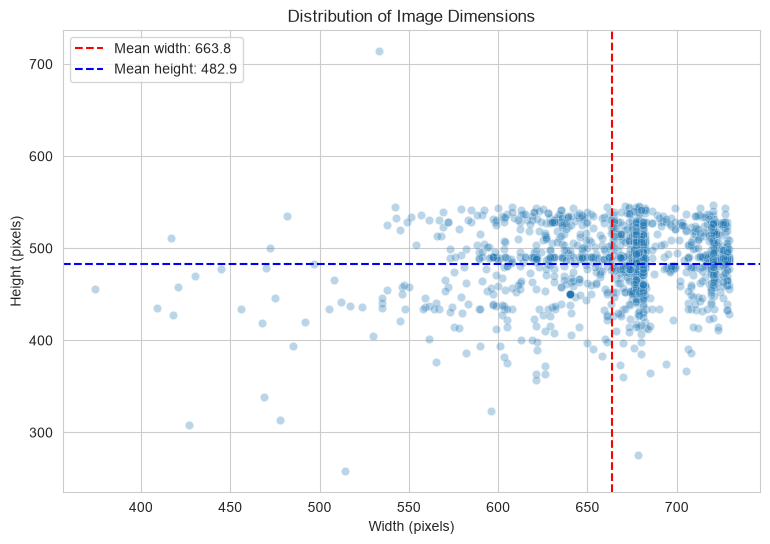

Total images: 1538
Width average: 663.8
Height average: 482.9


In [25]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.image import imread

# Correct training dataset path
train_path = '../inputs/Dataset_Clean/train'

# Get class labels
labels = [
    label for label in os.listdir(train_path)
    if os.path.isdir(os.path.join(train_path, label))
]

dim1, dim2 = [], []

# Loop through classes
for label in labels:

    class_path = os.path.join(train_path, label)

    for image_filename in os.listdir(class_path):

        image_path = os.path.join(class_path, image_filename)

        # Only process image files
        if not image_filename.lower().endswith(
            ('.png', '.jpg', '.jpeg')
        ):
            continue

        img = imread(image_path)

        # Supports grayscale and RGB images
        height, width = img.shape[:2]

        dim1.append(height)
        dim2.append(width)

# Calculate averages
dim1_mean = np.mean(dim1)
dim2_mean = np.mean(dim2)

# Plot dimensions
sns.set_style("whitegrid")

fig, axes = plt.subplots(figsize=(9, 6))

sns.scatterplot(
    x=dim2,
    y=dim1,
    alpha=0.3,
    ax=axes
)

# Average width: vertical line
axes.axvline(
    x=dim2_mean,
    color='red',
    linestyle='--',
    label=f'Mean width: {dim2_mean:.1f}'
)

# Average height: horizontal line
axes.axhline(
    y=dim1_mean,
    color='blue',
    linestyle='--',
    label=f'Mean height: {dim1_mean:.1f}'
)

axes.set_xlabel("Width (pixels)")
axes.set_ylabel("Height (pixels)")
axes.set_title("Distribution of Image Dimensions")

axes.legend()

plt.show()

print(f"Total images: {len(dim1)}")
print(f"Width average: {dim2_mean:.1f}")
print(f"Height average: {dim1_mean:.1f}")

Images size for training the model is the average from all images in the train set

In [26]:
image_shape = (dim1_mean, dim2_mean, 3)
image_shape

(np.float64(482.925877763329), np.float64(663.7971391417425), 3)

Save the imaghe shape embeddings

In [27]:
joblib.dump(value=image_shape ,
            filename=f"{file_path}/image_shape.pkl")

['outputs/v1/image_shape.pkl']

Average and variability of images per label 

Function to load images in an array (tensor)

In [28]:
from tensorflow.keras.preprocessing import image


def load_image_as_array(my_data_dir, new_size=(50, 50), n_images_per_label=20):

    X, y = np.array([], dtype='int'), np.array([], dtype='object')
    labels = os.listdir(my_data_dir)

    for label in labels:
        counter = 0
        for image_filename in os.listdir(my_data_dir + '/' + label):
            # n_images_per_label: we set a limit, since it may take too much time
            if counter < n_images_per_label:

                img = image.load_img(
                    my_data_dir + '/' + label + '/' + image_filename, target_size=new_size)
                if image.img_to_array(img).max() > 1:
                    img_resized = image.img_to_array(img) / 255
                else:
                    img_resized = image.img_to_array(img)

                X = np.append(X, img_resized).reshape(-1,
                                                    new_size[0], new_size[1], img_resized.shape[2])
                y = np.append(y, label)
                counter += 1

    return X, y

Load image shapes and labels in an array

In [29]:
import os

train_path = r'C:\python_projects\ML_2\inputs\Dataset_Clean\train'

for label in os.listdir(train_path):
    class_path = os.path.join(train_path, label)

    if os.path.isdir(class_path):
        print(f"\nClass: {label}")
        print(os.listdir(class_path)[:10])


Class: Non-Standard
['0078ea2fdd99f817b06d17a87d003b90bcb1af7b48239b93001976e6c08557a5.png', '00b57339504d57d72ffe3d422ded6b24e6c2a2fe19495b1a7a7dac08c16e174a.png', '00f91d896fcdc7d6ca324ed9ad170568ebb0e6c4530d6e646c359615a2a4ba6a.png', '00ff694b58ce74bac7d8fa53362873408c00ab24a3e89793f5448edb460198b5.png', '018e6e60772269d8f6ca2e73947d93adf99bc412b46f93b6a1e6e4ed27698b02.png', '01c39e390b0f515da484f79cceecf66aaeaaf19bdc3dbf8323d84cae019f01f8.png', '01c4d47b6e2b38d17eb999111eb141448a1d72391a5f498c3a0c63c2ae39eda2.png', '024b489fac8caeab7b196a914ceaf1a3cb517fa516c7a3569c5f0b071b05008b.png', '03208b09b26b2f41e0a2564e18787fc952aaeb77fc54daa45e395516773bbf12.png', '04160152c437d3939406273fc721746836a1c489ed6fdb740af061585beb26d6.png']

Class: Standard
['0001645a27c3d8292ad1bf8b9fd112aed3f5fdb09b9fdcf8d3e63086177a3b45.png', '008b8af26e0e4c538410b78e8d2b2eb01143cc2f5c7844c803551e1cc32ce791.png', '0113dfed6b82486bd9cf920b2cb7078035534ee86be744e1d954d44e0f89d3d7.png', '016efc5f3a4738c482b1b4e

In [30]:
import numpy as np
from pathlib import Path
from tensorflow.keras.utils import load_img, img_to_array

def load_image_as_array(my_data_dir, new_size=(256, 256),
                        n_images_per_label=30):

    X = []
    y = []

    data_dir = Path(my_data_dir)

    labels = sorted([
        folder.name for folder in data_dir.iterdir()
        if folder.is_dir()
    ])

    valid_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}

    for label_index, label in enumerate(labels):

        class_path = data_dir / label
        counter = 0

        for image_path in class_path.iterdir():

            if image_path.suffix.lower() not in valid_extensions:
                continue

            if counter >= n_images_per_label:
                break

            try:
                img = load_img(
                    image_path,
                    target_size=new_size,
                    color_mode='rgb'
                )

                img_array = img_to_array(img) / 255.0

                X.append(img_array)
                y.append(label_index)

                counter += 1

            except Exception as e:
                print(f"Could not load {image_path.name}: {e}")

        print(f"{label}: {counter} images loaded")

    return np.array(X), np.array(y)

In [31]:

X, y = load_image_as_array(
    my_data_dir=train_path,
    new_size=image_shape,
    n_images_per_label=30
)

print(X.shape, y.shape)

Could not load 0078ea2fdd99f817b06d17a87d003b90bcb1af7b48239b93001976e6c08557a5.png: 'numpy.float64' object cannot be interpreted as an integer
Could not load 00b57339504d57d72ffe3d422ded6b24e6c2a2fe19495b1a7a7dac08c16e174a.png: 'numpy.float64' object cannot be interpreted as an integer
Could not load 00f91d896fcdc7d6ca324ed9ad170568ebb0e6c4530d6e646c359615a2a4ba6a.png: 'numpy.float64' object cannot be interpreted as an integer
Could not load 00ff694b58ce74bac7d8fa53362873408c00ab24a3e89793f5448edb460198b5.png: 'numpy.float64' object cannot be interpreted as an integer
Could not load 018e6e60772269d8f6ca2e73947d93adf99bc412b46f93b6a1e6e4ed27698b02.png: 'numpy.float64' object cannot be interpreted as an integer
Could not load 01c39e390b0f515da484f79cceecf66aaeaaf19bdc3dbf8323d84cae019f01f8.png: 'numpy.float64' object cannot be interpreted as an integer
Could not load 01c4d47b6e2b38d17eb999111eb141448a1d72391a5f498c3a0c63c2ae39eda2.png: 'numpy.float64' object cannot be interpreted as an 

Plot and save mean and variability of images per label

In [32]:
def plot_mean_variability_per_labels(X, y, figsize=(12, 5), save_image=False):
    """
    The pseudo-code for the function is:
    * Loop over all labels
    * Subset an array for a given label
    * Calculate the mean and standard deviation
    * Create a figure displaying the mean and variability of images
    * Save the image
    """

    for label_to_display in np.unique(y):
        sns.set_style("white")

        y = y.reshape(-1, 1, 1)
        boolean_mask = np.any(y == label_to_display, axis=1).reshape(-1)
        arr = X[boolean_mask]

        avg_img = np.mean(arr, axis=0)
        std_img = np.std(arr, axis=0)
        print(f"==== Label {label_to_display} ====")
        print(f"Image Shape: {avg_img.shape}")
        fig, axes = plt.subplots(nrows=1, ncols=2, figsize=figsize)
        axes[0].set_title(f"Average image for label {label_to_display}")
        axes[0].imshow(avg_img, cmap='gray')
        axes[1].set_title(f"Variability image for label {label_to_display}")
        axes[1].imshow(std_img, cmap='gray')

        if save_image:
            plt.savefig(f"{file_path}/avg_var_{label_to_display}.png",
                        bbox_inches='tight', dpi=150)
        else:
            plt.tight_layout()
            plt.show()
            print("\n")

In [33]:

plot_mean_variability_per_labels(X=X, y=y, figsize=(12, 5), save_image=True)

Difference between average healthy and powdery mildew images

In [34]:
def subset_image_label(X, y, label_to_display):
    y = y.reshape(-1, 1, 1)
    boolean_mask = np.any(y == label_to_display, axis=1).reshape(-1)
    df = X[boolean_mask]
    return df

def diff_bet_avg_image_labels_data_as_array(X, y, label_1, label_2, figsize=(20, 5), save_image=False):
    """
    Checks if the labels exist in the set of unique labels
    Calculates the mean and difference for label1 and label2
    Plots a chart and saves it if save_image=True
    """
    sns.set_style("white")

    if (label_1 not in np.unique(y)) or (label_2 not in np.unique(y)):
        print(
            f"Either label {label} or label {label_2}, are not in {np.unique(y)} ")
        return

    # calculate mean from label1
    images_label = subset_image_label(X, y, label_1)
    label1_avg = np.mean(images_label, axis=0)

    # calculate mean from label2
    images_label = subset_image_label(X, y, label_2)
    label2_avg = np.mean(images_label, axis=0)

    # calculate difference and plot difference, avg label1 and avg label2
    difference_mean = label1_avg - label2_avg
    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=figsize)
    axes[0].imshow(label1_avg, cmap='gray')
    axes[0].set_title(f'Average {label_1}')
    axes[1].imshow(label2_avg, cmap='gray')
    axes[1].set_title(f'Average {label_2}')
    axes[2].imshow(difference_mean, cmap='gray')
    axes[2].set_title(f'Difference image: Avg {label_1} & {label_2}')
    if save_image:
        plt.savefig(f"{file_path}/avg_diff.png", bbox_inches='tight', dpi=150)
    else:
        plt.tight_layout()
        plt.show()



In [35]:
import os

train_path = r'C:\python_projects\ML_2\inputs\Dataset_Clean\train'

for label in os.listdir(train_path):
    class_path = os.path.join(train_path, label)

    if os.path.isdir(class_path):
        print(f"\nClass: {label}")
        print(os.listdir(class_path)[:10])


Class: Non-Standard
['0078ea2fdd99f817b06d17a87d003b90bcb1af7b48239b93001976e6c08557a5.png', '00b57339504d57d72ffe3d422ded6b24e6c2a2fe19495b1a7a7dac08c16e174a.png', '00f91d896fcdc7d6ca324ed9ad170568ebb0e6c4530d6e646c359615a2a4ba6a.png', '00ff694b58ce74bac7d8fa53362873408c00ab24a3e89793f5448edb460198b5.png', '018e6e60772269d8f6ca2e73947d93adf99bc412b46f93b6a1e6e4ed27698b02.png', '01c39e390b0f515da484f79cceecf66aaeaaf19bdc3dbf8323d84cae019f01f8.png', '01c4d47b6e2b38d17eb999111eb141448a1d72391a5f498c3a0c63c2ae39eda2.png', '024b489fac8caeab7b196a914ceaf1a3cb517fa516c7a3569c5f0b071b05008b.png', '03208b09b26b2f41e0a2564e18787fc952aaeb77fc54daa45e395516773bbf12.png', '04160152c437d3939406273fc721746836a1c489ed6fdb740af061585beb26d6.png']

Class: Standard
['0001645a27c3d8292ad1bf8b9fd112aed3f5fdb09b9fdcf8d3e63086177a3b45.png', '008b8af26e0e4c538410b78e8d2b2eb01143cc2f5c7844c803551e1cc32ce791.png', '0113dfed6b82486bd9cf920b2cb7078035534ee86be744e1d954d44e0f89d3d7.png', '016efc5f3a4738c482b1b4e

In [36]:
import numpy as np

train_path = r'C:\python_projects\ML_2\inputs\Dataset_Clean\train'
image_shape = (256, 256)

X, y = load_image_as_array(
    my_data_dir=train_path,
    new_size=image_shape,
    n_images_per_label=30
)

print("X shape:", X.shape)
print("y shape:", y.shape)

Non-Standard: 30 images loaded
Standard: 30 images loaded
X shape: (60, 256, 256, 3)
y shape: (60,)


In [37]:
diff_bet_avg_image_labels_data_as_array(
    X=X,
    y=y,
    label_1='Non-Standard',
    label_2='Standard',
    figsize=(12, 10),
    save_image=True
)

Either label Standard or label Standard, are not in [0 1] 


In [38]:

diff_bet_avg_image_labels_data_as_array(X=X, y=y,
                                        label_1='Standard', label_2='Non-Standard',
                                        figsize=(12, 10),
                                        save_image=True
                                        )

Either label Standard or label Non-Standard, are not in [0 1] 


Image Montage

In [39]:
import itertools
import random
sns.set_style("white")


def image_montage(dir_path, label_to_display, nrows, ncols, figsize=(15, 10)):
    """
    if the label exists in the directory
    check if your montage space is greater than the subset size
    create a list of axes indices based on nrows and ncols
    create a Figure and display images
    in this loop, load and plot the given image
    """

    labels = os.listdir(dir_path)

    # subset the class you are interested to display
    if label_to_display in labels:

        # checks if your montage space is greater than the subset size
        images_list = os.listdir(dir_path + '/' + label_to_display)
        if nrows * ncols < len(images_list):
            img_idx = random.sample(images_list, nrows * ncols)
        else:
            print(
                f"Decrease nrows or ncols to create your montage. \n"
                f"There are {len(images_list)} in your subset. "
                f"You requested a montage with {nrows * ncols} spaces")
            return
        
        # create a list of axes indices based on nrows and ncols
        list_rows = range(0, nrows)
        list_cols = range(0, ncols)
        plot_idx = list(itertools.product(list_rows, list_cols))

        # create a Figure and display images
        fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize)
        for x in range(0, nrows*ncols):
            img = imread(dir_path + '/' + label_to_display + '/' + img_idx[x])
            img_shape = img.shape
            axes[plot_idx[x][0], plot_idx[x][1]].imshow(img)
            axes[plot_idx[x][0], plot_idx[x][1]].set_title(
                f"Width {img_shape[1]}px x Height {img_shape[0]}px")
            axes[plot_idx[x][0], plot_idx[x][1]].set_xticks([])
            axes[plot_idx[x][0], plot_idx[x][1]].set_yticks([])
        plt.tight_layout()
        plt.show()

    else:
        print("The label you selected doesn't exist.")
        print(f"The existing options are: {labels}")

In [40]:
from pathlib import Path

root = Path(r"C:\python_projects\ML_2\inputs\Dataset_Clean")

for folder in root.rglob("*"):
    if folder.is_dir():
        print(folder.relative_to(root))

Non-standard
Standard
test
train
validation
test\Non-Standard
test\Standard
train\Non-Standard
train\Standard
validation\Non-Standard
validation\Standard


In [41]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"C:\python_projects\ML_2")

DATASET_DIR = (
    PROJECT_DIR / "inputs" / "Dataset_Clean" / "train"
)

OUTPUT_DIR = PROJECT_DIR / "jupyter_notebooks" / "outputs" / "v1"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def load_images(class_name):
    folder = DATASET_DIR / class_name
    images = []

    if not folder.is_dir():
        raise FileNotFoundError(f"Folder not found: {folder}")

    for path in sorted(folder.rglob("*")):
        if path.suffix.lower() not in {".png", ".jpg", ".jpeg"}:
            continue

        try:
            with Image.open(path) as img:
                img = img.convert("L").resize((256, 256))
                images.append(
                    np.asarray(img, dtype=np.float32) / 255.0
                )
        except Exception as e:
            print(f"Could not load {path.name}: {e}")

    if not images:
        raise ValueError(f"No images found in {folder}")

    return np.stack(images)

standard = load_images("Standard")
non_standard = load_images("Non-Standard")

print("Standard:", standard.shape)
print("Non-Standard:", non_standard.shape)

avg_standard = standard.mean(axis=0)
avg_non_standard = non_standard.mean(axis=0)

var_standard = standard.std(axis=0)
var_non_standard = non_standard.std(axis=0)

avg_diff = avg_standard - avg_non_standard

def save_image(image, filename, title, cmap="gray"):
    plt.figure(figsize=(6, 5))
    plt.imshow(image, cmap=cmap)
    plt.title(title)
    plt.colorbar()
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=200)
    plt.close()

save_image(var_standard, "avg_var_standard.png",
           "Standard Image Variability")

save_image(var_non_standard, "avg_var_non_standard.png",
           "Non-Standard Image Variability")

save_image(avg_diff, "avg_diff.png",
           "Difference of Average Images", cmap="coolwarm")

print("All three images saved successfully.")

Standard: (1098, 256, 256)
Non-Standard: (440, 256, 256)
All three images saved successfully.


In [42]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Project directories
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "jupyter_notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATASET_DIR = PROJECT_DIR / "inputs" / "Dataset_Clean" /"train"
OUTPUT_DIR = PROJECT_DIR / "jupyter_notebooks" / "outputs" / "v1"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = (224, 224)

def load_images(class_name):

    folder = DATASET_DIR / class_name

    images = []

    for path in sorted(folder.rglob("*")):

        if path.suffix.lower() not in [
            ".png", ".jpg", ".jpeg"
        ]:
            continue

        with Image.open(path) as img:
            img = img.convert("L")
            img = img.resize(IMAGE_SIZE)

            images.append(
                np.asarray(img, dtype=np.float32) / 255.0
            )

    if not images:
        raise ValueError(
            f"No images found in {folder}"
        )

    return np.stack(images)


# Load both classes
standard = load_images("Standard")
non_standard = load_images("Non-Standard")

# Calculate average images
avg_standard = np.mean(standard, axis=0)
avg_non_standard = np.mean(non_standard, axis=0)

# Calculate variability
var_standard = np.std(standard, axis=0)
var_non_standard = np.std(non_standard, axis=0)

# Difference between averages
avg_diff = avg_standard - avg_non_standard


def save_image(image, filename, title, cmap="gray"):

    plt.figure(figsize=(6, 6))
    plt.imshow(image, cmap=cmap)
    plt.title(title)
    plt.axis("off")
    plt.colorbar()
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()


# Save images
save_image(
    var_standard,
    "avg_var_standard.png",
    "Standard Image Variability"
)

save_image(
    var_non_standard,
    "avg_var_non_standard.png",
    "Non-Standard Image Variability"
)

save_image(
    avg_diff,
    "avg_diff.png",
    "Difference of Average Images",
    cmap="coolwarm"
)

print("Images saved successfully!")

Images saved successfully!


Non-Standard


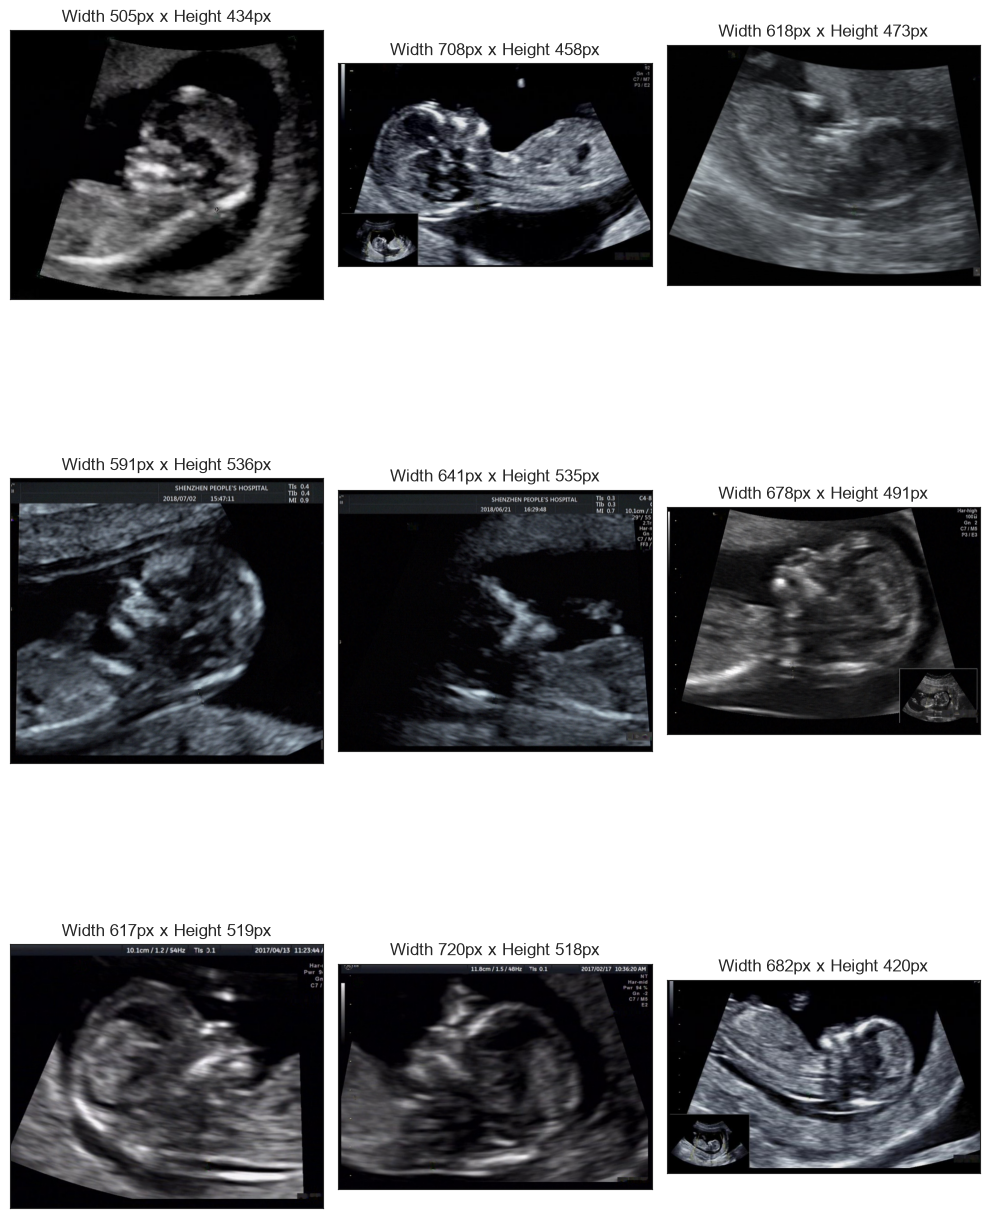



Standard


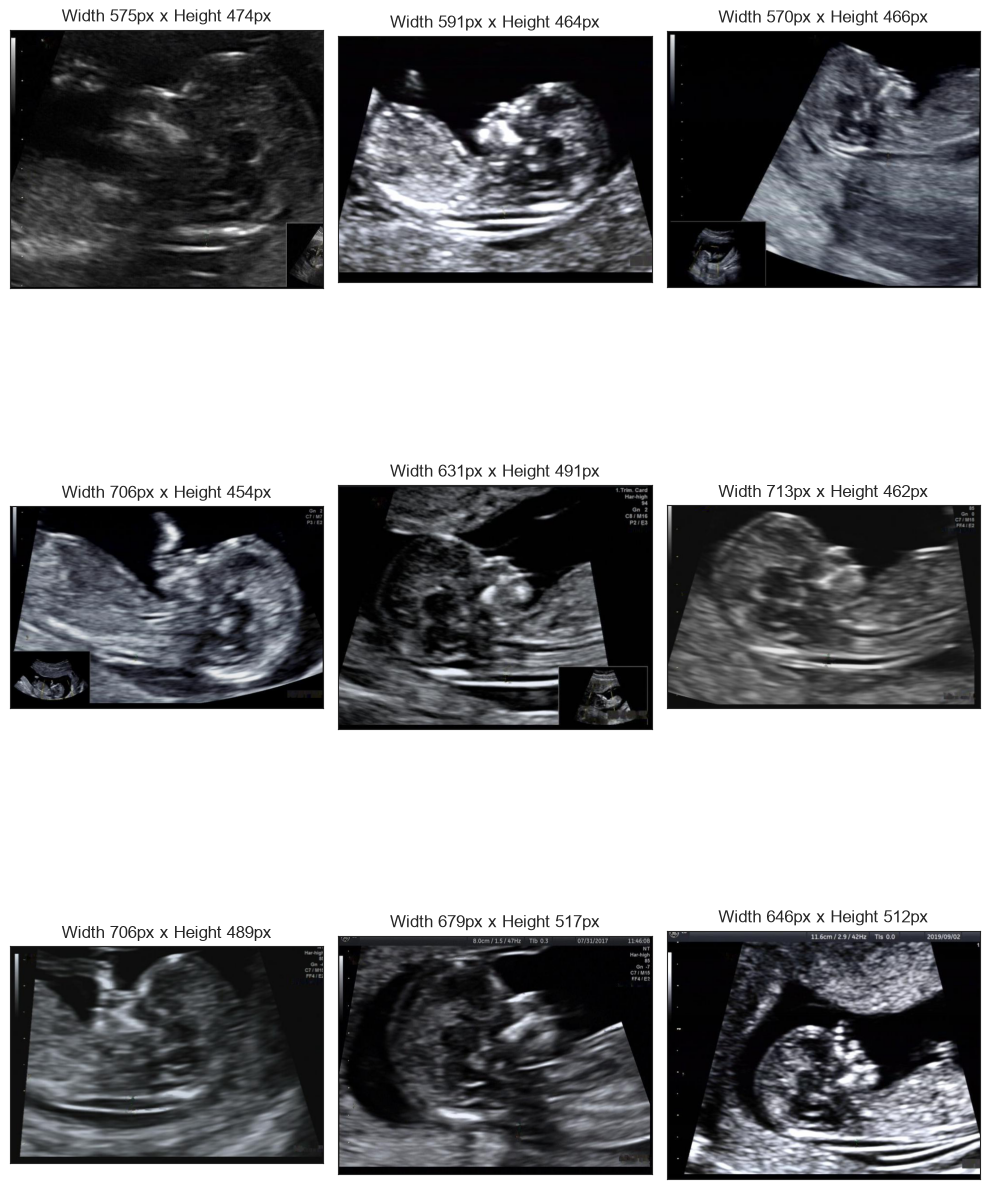

In [43]:
for label in labels:
    print(label)
    image_montage(dir_path=train_path,
                label_to_display=label,
                nrows=3, ncols=3,
                figsize=(10, 15)
                
                )
    print("\n")